1.1 Create your first RDKit molecule

In [1]:

%pip install -q rdkit


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 31.8/31.8 MB 29.4 MB/s eta 0:00:00


In [2]:

import rdkit
print("RDKit version:", rdkit.__version__)


RDKit version: 2026.09.1


SMILES: CCO
Molecule: <rdkit.Chem.rdchem.Mol object at 0x7b340d827bc0>
Number of atoms: 3
Number of bonds: 2


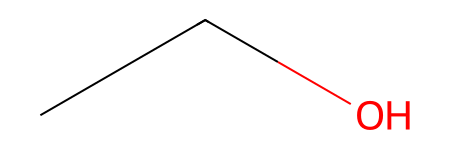

In [3]:

from rdkit import Chem

# Represent ethanol using SMILES
smiles = "CCO"

# Convert SMILES into an RDKit molecule
molecule = Chem.MolFromSmiles(smiles)

# Inspect the molecular representation
print("SMILES:", smiles)
print("Molecule:", molecule)
print("Number of atoms:", molecule.GetNumAtoms())
print("Number of bonds:", molecule.GetNumBonds())

# Display its 2D structure
display(molecule)


The full chemical formula is C₂H₆O, but RDKit reports three atoms because hydrogens are implicit by default.

1.2 Understanding SMILES and molecular structure

In [4]:

# Examine each atom in the ethanol molecule
for atom in molecule.GetAtoms():
    print(
        "Atom index:", atom.GetIdx(),
        "| Element:", atom.GetSymbol(),
        "| Atomic number:", atom.GetAtomicNum(),
        "| Total hydrogens:", atom.GetTotalNumHs()
    )


Atom index: 0 | Element: C | Atomic number: 6 | Total hydrogens: 3
Atom index: 1 | Element: C | Atomic number: 6 | Total hydrogens: 2
Atom index: 2 | Element: O | Atomic number: 8 | Total hydrogens: 1


An atomic number tells us how many protons are present in the nucleus of an atom.

1.3 How RDKit identifies bonds between atoms.

Start atom: 0 | End atom: 1 | Bond type: SINGLE
Start atom: 1 | End atom: 2 | Bond type: SINGLE


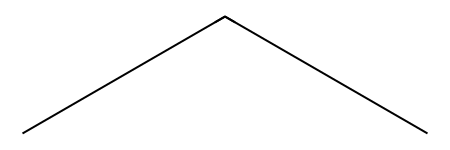

In [5]:

# Create propane from its SMILES
propane = Chem.MolFromSmiles("CCC")

# Examine bonds in propane
for bond in propane.GetBonds():
    print(
        "Start atom:", bond.GetBeginAtomIdx(),
        "| End atom:", bond.GetEndAtomIdx(),
        "| Bond type:", bond.GetBondType()
    )

# Display propane
display(propane)


Start Atom and End Atom tell us which two atoms are connected by a chemical bond.



1.4 Understanding single, double, and triple bonds

Molecule: Ethane
SMILES: CC
Bond type: SINGLE


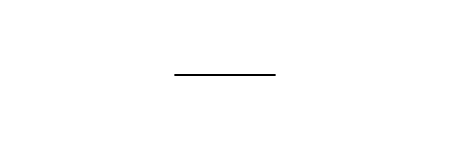

--------------------
Molecule: Ethene
SMILES: C=C
Bond type: DOUBLE


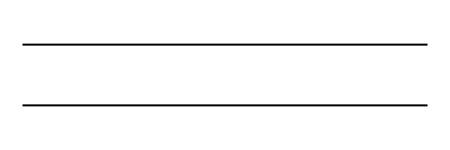

--------------------
Molecule: Ethyne
SMILES: C#C
Bond type: TRIPLE


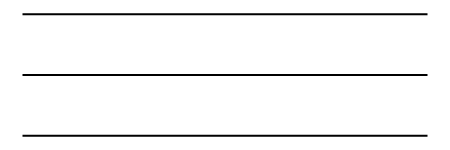

--------------------


In [6]:

from rdkit import Chem

molecules = {
    "Ethane": "CC",
    "Ethene": "C=C",
    "Ethyne": "C#C"
}

for name, smiles in molecules.items():
    mol = Chem.MolFromSmiles(smiles)

    print("Molecule:", name)
    print("SMILES:", smiles)

    for bond in mol.GetBonds():
        print("Bond type:", bond.GetBondType())

    display(mol)
    print("--------------------")


1.5 Molecular descriptors

A molecular descriptor is a numerical property calculated from a molecule. Machine learning models can use these numbers to predict properties relevant to drug discovery.

For example:
- Molecular weight: How heavy the molecule is.
- LogP: An estimate of how strongly the neutral molecule prefers a nonpolar environment over water.
- TPSA: Topological polar surface area, related to molecular polarity.
- H-bond donors and acceptors: Features relevant to molecular interactions.

In [7]:

from rdkit import Chem
from rdkit.Chem import Descriptors

# Create an ethanol molecule
mol = Chem.MolFromSmiles("CCO")

# Calculate molecular descriptors
print("Molecular Weight:", Descriptors.MolWt(mol))
print("LogP:", Descriptors.MolLogP(mol))
print("TPSA:", Descriptors.TPSA(mol))
print("H-Bond Donors:", Descriptors.NumHDonors(mol))
print("H-Bond Acceptors:", Descriptors.NumHAcceptors(mol))


Molecular Weight: 46.069
LogP: -0.0014000000000000123
TPSA: 20.23
H-Bond Donors: 1
H-Bond Acceptors: 1


1.6 Understand LogP

LogP measures how a neutral molecule distributes between two liquids: octanol (oil-like) and water.

                   LogP = Log10(Coctanal/Cwater)

Positive LogP: The molecule prefers the octanol phase.

Negative LogP: The molecule prefers the water phase.

LogP near zero: The molecule partitions approximately equally between them.                  



Your ethanol result is −0.0014, suggesting an approximately equal octanol/water partition according to RDKit's calculated model. This is a prediction, not a measured experimental value.

1.7 Understanding TPSA

TPSA = Topological Polar Surface Area.

It estimates the molecular surface area associated with polar atoms, primarily oxygen and nitrogen, including hydrogens attached to them.

TPSA is measured in square ångströms (Å²).

Why does it matter?
- TPSA helps estimate a molecule's polarity.
- It is useful when studying membrane permeability and oral drug absorption.
- Higher TPSA often makes passive membrane crossing more difficult, although other molecular properties also matter.

Your ethanol molecule has:

TPSA = 20.23 Å²

This is relatively low, meaning ethanol has a small polar surface area.

Question: Suppose two molecules are otherwise similar. Molecule A has TPSA = 25 Å², while Molecule B has TPSA = 150 Å². Which would generally be expected to cross a lipid membrane more easily by passive diffusion?

Molecule A (TPSA = 25 Å²)  ✅

Molecule B (TPSA = 150 Å²)

TPSA has no relationship to membrane permeability

Higher TPSA → Greater polar surface area → Generally more difficult passive diffusion through lipid membranes.

1.8 — Morgan fingerprints

A Morgan fingerprint converts a molecule's structural features into a numerical representation that a machine learning model can use.

For example, a 2048-bit fingerprint contains 2048 positions, each represented by 0 or 1. These encode information about local atomic environments.

In [8]:

from rdkit import Chem
from rdkit.Chem import rdFingerprintGenerator

# Create an ethanol molecule
mol = Chem.MolFromSmiles("CCO")

# Create Morgan fingerprint generator
generator = rdFingerprintGenerator.GetMorganGenerator(
    radius=2,
    fpSize=2048
)

# Generate fingerprint
fingerprint = generator.GetFingerprint(mol)

print("Fingerprint size:", fingerprint.GetNumBits())
print("Number of active bits:", fingerprint.GetNumOnBits())
print("Active bit positions:", list(fingerprint.GetOnBits()))


Fingerprint size: 2048
Number of active bits: 6
Active bit positions: [80, 222, 294, 807, 1057, 1410]


1.9 — Understand the Morgan fingerprint

1. fpSize=2048

Every molecule gets a fingerprint containing 2048 binary positions, numbered 0 through 2047.

Your ethanol fingerprint has six positions set to 1. All remaining 2042 positions are 0.

2. radius=2

RDKit examines each atom and its surrounding chemical environment up to two bonds away.

3. Active bits

The six active positions represent hashed information about ethanol's atomic environments.

A bit position does not directly identify a particular atom, and multiple structural environments can map to the same position (a hash collision).

1.10 — Compare fingerprint sizes experimentally

In [9]:

from rdkit import Chem
from rdkit.Chem import rdFingerprintGenerator

mol = Chem.MolFromSmiles("CCO")

for size in [128, 512, 2048, 4096]:
    generator = rdFingerprintGenerator.GetMorganGenerator(
        radius=2,
        fpSize=size
    )

    fp = generator.GetFingerprint(mol)

    print("Fingerprint size:", fp.GetNumBits())
    print("Active bits:", fp.GetNumOnBits())
    print("Active positions:", list(fp.GetOnBits()))
    print("-------------------------")


Fingerprint size: 128
Active bits: 6
Active positions: [2, 33, 38, 39, 80, 94]
-------------------------
Fingerprint size: 512
Active bits: 6
Active positions: [33, 80, 222, 294, 295, 386]
-------------------------
Fingerprint size: 2048
Active bits: 6
Active positions: [80, 222, 294, 807, 1057, 1410]
-------------------------
Fingerprint size: 4096
Active bits: 6
Active positions: [807, 2128, 2270, 2342, 3105, 3458]
-------------------------


1.11 — Calculate molecular similarity

How Morgan fingerprints can be used to compare two molecules.

We will calculate Tanimoto similarity, a commonly used measure of chemical fingerprint similarity.

Tanimoto similarity ranges from 0 to 1:
- 0: No shared active fingerprint bits.
- 1: Identical bit fingerprints.
- Values between 0 and 1 indicate different degrees of fingerprint similarity.

A similarity of 1 does not necessarily prove two molecules are chemically identical.

In [10]:

from rdkit import Chem, DataStructs
from rdkit.Chem import rdFingerprintGenerator

# Create three molecules
ethanol = Chem.MolFromSmiles("CCO")
propanol = Chem.MolFromSmiles("CCCO")
benzene = Chem.MolFromSmiles("c1ccccc1")

# Generate 2048-bit Morgan fingerprints
generator = rdFingerprintGenerator.GetMorganGenerator(
    radius=2,
    fpSize=2048
)

fp_ethanol = generator.GetFingerprint(ethanol)
fp_propanol = generator.GetFingerprint(propanol)
fp_benzene = generator.GetFingerprint(benzene)

# Calculate molecular similarities
similarity_1 = DataStructs.TanimotoSimilarity(
    fp_ethanol, fp_propanol
)

similarity_2 = DataStructs.TanimotoSimilarity(
    fp_ethanol, fp_benzene
)

print("Ethanol vs Propanol:", round(similarity_1, 3))
print("Ethanol vs Benzene:", round(similarity_2, 3))


Ethanol vs Propanol: 0.556
Ethanol vs Benzene: 0.0


What do these results mean?
Ethanol vs Propanol = 0.556

These molecules share several structural features, including a carbon chain and an –OH group. Therefore, their Morgan fingerprints have overlapping active bits.

Ethanol vs Benzene = 0.000

Their fingerprints share no active bits under the selected radius=2 and fpSize=2048 settings.

This does not mean the molecules have absolutely nothing in common chemically. It means their particular fingerprint representations have no overlapping active positions.

A Tanimoto similarity of 1.0 means the two binary fingerprints are identical. However, different chemical structures can sometimes produce identical fingerprints because fingerprints are compressed representations.

1.12 — Required reading

Pat Walters' article “AI in Drug Discovery — Please Stop Fishing in the Bathtub!

1.13 — Prepare the ChEMBL dataset

In [11]:

%pip install -q chembl_webresource_client


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 55.2/55.2 kB 795.0 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 70.8/70.8 kB 2.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 74.8/74.8 kB 3.6 MB/s eta 0:00:00


1.14 — Connect Python to ChEMBL

Objective: Verify that Python can communicate with the ChEMBL database before retrieving real molecular data.

ChEMBL is a scientific database containing molecules, biological targets, and experimentally measured bioactivities.

In [12]:

from chembl_webresource_client.new_client import new_client

# Connect to the ChEMBL molecule resource
molecule_client = new_client.molecule

# Request one molecule using its ChEMBL ID
result = molecule_client.get("CHEMBL25")

# Display basic information
print("ChEMBL ID:", result["molecule_chembl_id"])
print("Preferred Name:", result["pref_name"])
print("Molecule Type:", result["molecule_type"])


/usr/local/lib/python3.13/dist-packages/chembl_webresource_client/__init__.py:4: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  __version__ = __import__('pkg_resources').get_distribution('chembl_webresource_client').version


ChEMBL ID: CHEMBL25
Preferred Name: ASPIRIN
Molecule Type: Small molecule


1.15 — Retrieve aspirin's molecular structure

Molecule: ASPIRIN
ChEMBL ID: CHEMBL25
SMILES: CC(=O)Oc1ccccc1C(=O)O


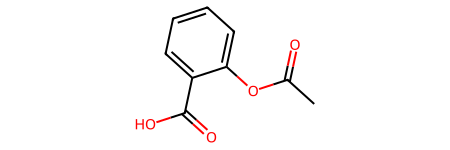

In [13]:

# Extract aspirin's molecular structure
structure = result["molecule_structures"]

# Retrieve canonical SMILES
smiles = structure["canonical_smiles"]

print("Molecule:", result["pref_name"])
print("ChEMBL ID:", result["molecule_chembl_id"])
print("SMILES:", smiles)

# Convert SMILES into an RDKit molecule
aspirin = Chem.MolFromSmiles(smiles)

# Display molecular structure
display(aspirin)


1.16 — Retrieve 100 molecules from ChEMBL

In [14]:

import pandas as pd
from chembl_webresource_client.new_client import new_client

# Connect to the ChEMBL database
molecule_client = new_client.molecule

# Retrieve the first 100 small-molecule records
records = molecule_client.filter(
    molecule_type="Small molecule"
).only(
    "molecule_chembl_id",
    "pref_name",
    "molecule_structures"
)[:100]

# Convert records into a DataFrame
df = pd.DataFrame(list(records))

# Extract canonical SMILES
df["SMILES"] = df["molecule_structures"].apply(
    lambda x: x.get("canonical_smiles")
    if isinstance(x, dict) else None
)

# Keep molecules with available SMILES
df = df.dropna(subset=["SMILES"]).copy()

# Display dataset information
print("Number of molecules:", len(df))
print("Dataset columns:", df.columns.tolist())

display(df[["molecule_chembl_id", "pref_name", "SMILES"]].head())


Number of molecules: 100
Dataset columns: ['molecule_chembl_id', 'molecule_structures', 'pref_name', 'SMILES']


,molecule_chembl_id,pref_name,SMILES
0,CHEMBL6329,None,Cc1cc(-n2ncc(=O)[nH]c2=O)ccc1C(=O)c1ccccc1Cl
1,CHEMBL6328,None,Cc1cc(-n2ncc(=O)[nH]c2=O)ccc1C(=O)c1ccc(C#N)cc1
2,CHEMBL265667,None,Cc1cc(-n2ncc(=O)[nH]c2=O)cc(C)c1C(O)c1ccc(Cl)cc1
3,CHEMBL6362,None,Cc1ccc(C(=O)c2ccc(-n3ncc(=O)[nH]c3=O)cc2)cc1
4,CHEMBL267864,None,Cc1cc(-n2ncc(=O)[nH]c2=O)ccc1C(=O)c1ccc(Cl)cc1


1.17 — Validate molecular structures

Before calculating molecular descriptors, we must check whether RDKit can interpret every SMILES string in our dataset.

In [15]:

from rdkit import Chem

# Convert SMILES strings into RDKit molecules
df["Molecule"] = df["SMILES"].apply(
    Chem.MolFromSmiles
)

# Check valid and invalid molecules
valid_count = df["Molecule"].notna().sum()
invalid_count = df["Molecule"].isna().sum()

print("Total molecules:", len(df))
print("Valid molecules:", valid_count)
print("Invalid molecules:", invalid_count)

# Remove invalid molecules
df = df.dropna(subset=["Molecule"]).copy()

print("Final dataset size:", len(df))


Total molecules: 100
Valid molecules: 100
Invalid molecules: 0
Final dataset size: 100


1.18 — Calculate molecular descriptors for 100 molecules

Objective: Calculate five molecular properties for every molecule in our ChEMBL dataset, rather than for just one molecule.

In [16]:

from rdkit.Chem import Descriptors

# Calculate molecular descriptors for all molecules
df["Molecular_Weight"] = df["Molecule"].apply(
    Descriptors.MolWt
)

df["LogP"] = df["Molecule"].apply(
    Descriptors.MolLogP
)

df["TPSA"] = df["Molecule"].apply(
    Descriptors.TPSA
)

df["HBD"] = df["Molecule"].apply(
    Descriptors.NumHDonors
)

df["HBA"] = df["Molecule"].apply(
    Descriptors.NumHAcceptors
)

# Display the calculated properties
columns = [
    "molecule_chembl_id",
    "Molecular_Weight",
    "LogP",
    "TPSA",
    "HBD",
    "HBA"
]

display(df[columns].head())

print("Molecules processed:", len(df))
print("Missing descriptor values:",
      df[columns[1:]].isna().sum().sum())


,molecule_chembl_id,Molecular_Weight,LogP,TPSA,HBD,HBA
0,CHEMBL6329,341.754,2.11362,84.82,1,4
1,CHEMBL6328,332.319,1.33190,108.61,1,5
2,CHEMBL265667,357.797,2.27274,87.98,2,4
3,CHEMBL6362,307.309,1.46022,84.82,1,4
4,CHEMBL267864,341.754,2.11362,84.82,1,4


Molecules processed: 100
Missing descriptor values: 0


1.19 — Generate Morgan fingerprints for all 100 molecules

Objective: Convert every molecule into a 2048-bit numerical fingerprint, just as you did in your earlier AqSolDB machine learning project.
This time, we will generate fingerprints for an entire ChEMBL dataset.

In [17]:

import numpy as np
from rdkit.Chem import rdFingerprintGenerator

# Create Morgan fingerprint generator
generator = rdFingerprintGenerator.GetMorganGenerator(
    radius=2,
    fpSize=2048
)

# Generate fingerprints for all molecules
fingerprints = [
    np.array(generator.GetFingerprint(mol), dtype=np.int8)
    for mol in df["Molecule"]
]

# Convert fingerprints into a NumPy matrix
X = np.array(fingerprints)

print("Fingerprint matrix shape:", X.shape)
print("First molecule fingerprint size:", len(X[0]))
print("First molecule active bits:", np.sum(X[0]))
print("Unique values:", np.unique(X))


Fingerprint matrix shape: (100, 2048)
First molecule fingerprint size: 2048
First molecule active bits: 45
Unique values: [0 1]


1.20 — Visualize molecular weight distribution

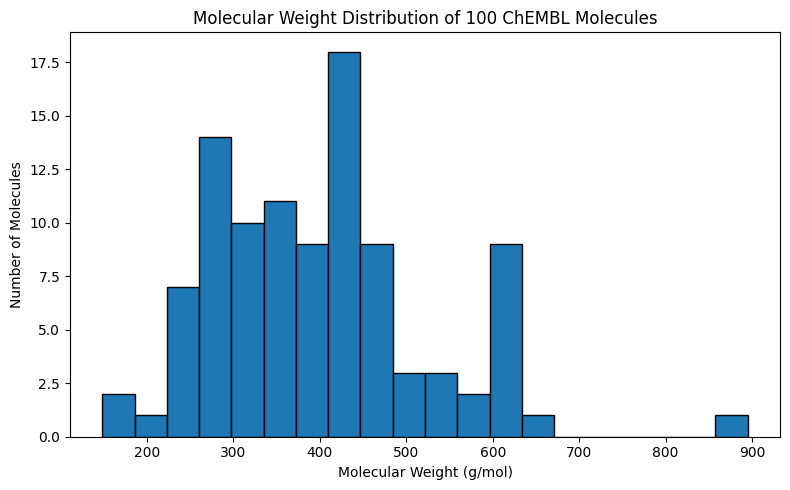

Mean molecular weight: 399.83
Minimum molecular weight: 148.21
Maximum molecular weight: 895.1


In [18]:

import matplotlib.pyplot as plt

# Plot molecular weight distribution
plt.figure(figsize=(8, 5))

plt.hist(
    df["Molecular_Weight"],
    bins=20,
    edgecolor="black"
)

plt.xlabel("Molecular Weight (g/mol)")
plt.ylabel("Number of Molecules")
plt.title("Molecular Weight Distribution of 100 ChEMBL Molecules")

plt.tight_layout()
plt.show()

# Calculate summary statistics
print("Mean molecular weight:",
      round(df["Molecular_Weight"].mean(), 2))

print("Minimum molecular weight:",
      round(df["Molecular_Weight"].min(), 2))

print("Maximum molecular weight:",
      round(df["Molecular_Weight"].max(), 2))


The molecule near 900 g/mol is a high-molecular-weight outlier, but molecular weight alone cannot tell us whether it is a good or bad drug candidate.

1.21 — Visualize LogP distribution

We will now analyze the lipophilicity of your 100 ChEMBL molecules.

Positive LogP indicates greater preference for octanol relative to water.



Negative LogP indicates greater preference for water.



Higher LogP does not automatically mean a better drug.

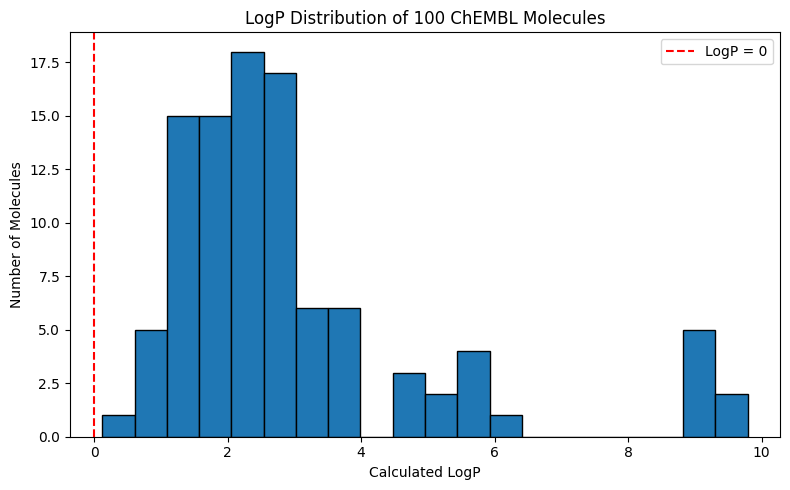

Mean LogP: 3.01
Minimum LogP: 0.12
Maximum LogP: 9.79
Molecules with LogP > 5: 14


In [19]:

import matplotlib.pyplot as plt

# Plot the LogP distribution
plt.figure(figsize=(8, 5))

plt.hist(
    df["LogP"],
    bins=20,
    edgecolor="black"
)

plt.xlabel("Calculated LogP")
plt.ylabel("Number of Molecules")
plt.title("LogP Distribution of 100 ChEMBL Molecules")

# Reference line for LogP = 0
plt.axvline(
    x=0,
    color="red",
    linestyle="--",
    label="LogP = 0"
)

plt.legend()
plt.tight_layout()
plt.show()

# Summary statistics
print("Mean LogP:", round(df["LogP"].mean(), 2))
print("Minimum LogP:", round(df["LogP"].min(), 2))
print("Maximum LogP:", round(df["LogP"].max(), 2))

print("Molecules with LogP > 5:",
      (df["LogP"] > 5).sum())


1.22 — Visualize TPSA distribution

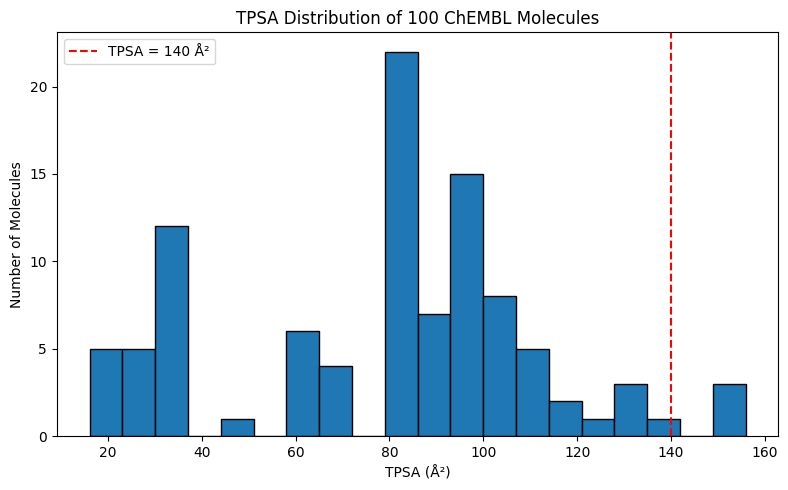

Mean TPSA: 79.52
Minimum TPSA: 16.13
Maximum TPSA: 155.9
Molecules with TPSA > 140: 3


In [20]:

import matplotlib.pyplot as plt

# Plot TPSA distribution
plt.figure(figsize=(8, 5))

plt.hist(
    df["TPSA"],
    bins=20,
    edgecolor="black"
)

# Reference threshold
plt.axvline(
    x=140,
    color="red",
    linestyle="--",
    label="TPSA = 140 Å²"
)

plt.xlabel("TPSA (Å²)")
plt.ylabel("Number of Molecules")
plt.title("TPSA Distribution of 100 ChEMBL Molecules")

plt.legend()
plt.tight_layout()
plt.show()

# Summary statistics
print("Mean TPSA:", round(df["TPSA"].mean(), 2))
print("Minimum TPSA:", round(df["TPSA"].min(), 2))
print("Maximum TPSA:", round(df["TPSA"].max(), 2))

print("Molecules with TPSA > 140:",
      (df["TPSA"] > 140).sum())


Your dataset shows that 97 out of 100 molecules have TPSA values at or below 140 Å², while 3 exceed this guideline.

The histogram also shows a prominent group of molecules around 80–105 Å².

This is useful for investigating potential passive membrane permeability, but TPSA alone cannot establish whether a molecule will be orally absorbed.

1.23 — Final dataset quality check

In [21]:

# Final Day 1 dataset quality check

print("Total molecules:", len(df))
print("Fingerprint matrix shape:", X.shape)

print("Missing SMILES:",
      df["SMILES"].isna().sum())

print("Missing molecular descriptors:",
      df[[
          "Molecular_Weight",
          "LogP",
          "TPSA",
          "HBD",
          "HBA"
      ]].isna().sum().sum())

print("Duplicate ChEMBL IDs:",
      df["molecule_chembl_id"].duplicated().sum())

print("Duplicate SMILES:",
      df["SMILES"].duplicated().sum())


Total molecules: 100
Fingerprint matrix shape: (100, 2048)
Missing SMILES: 0
Missing molecular descriptors: 0
Duplicate ChEMBL IDs: 0
Duplicate SMILES: 0


Duplicates may distort molecular distributions and can cause data leakage when building machine learning models.

TPSA (Å²)	                  General interpretation

0–40	       Low polarity; passive membrane permeability may be favorable

40–90	Often a useful range for orally administered small molecules

90–140	Higher polarity; passive permeability may become more challenging

Above 140	Greater risk of poor passive permeability, particularly for conventional oral drugs

1.24 — Save your cleaned dataset

In [22]:

# Select the columns needed for our dataset
export_columns = [
    "molecule_chembl_id",
    "pref_name",
    "SMILES",
    "Molecular_Weight",
    "LogP",
    "TPSA",
    "HBD",
    "HBA"
]

# Export the cleaned dataset
df[export_columns].to_csv(
    "Week_01_Day_01_ChEMBL_100.csv",
    index=False
)

print("Dataset saved successfully!")
print("Rows:", len(df[export_columns]))
print("Columns:", len(export_columns))


Dataset saved successfully!
Rows: 100
Columns: 8
